# Projeto de Previsão Econômica com Agente Assistivo 
**Este projeto tem como objetivo desenvolver um sistema estruturado de coleta, tratamento e modelagem de dados macroeconômicos brasileiros, com foco na projeção do IPCA (inflação) e da taxa SELIC (juros básicos) até o ano de 2030.**

**A proposta integra técnicas de econometria de séries temporais (ARIMA e SARIMA) para estimar a dinâmica dessas variáveis, considerando persistência, possíveis tendências e sazonalidade.**

**O sistema contempla:**

- *Organização e consolidação das séries históricas*
- *Testes de estacionariedade*
- *Seleção automática de modelos via critérios de informação (AIC/BIC)*
- *Geração de projeções mensais*
- *Construção de cenários (base, pessimista e otimista)*

*Como diferencial, o projeto incorpora um agente assistivo capaz de interpretar os resultados econométricos e apoiar a análise dos cenários projetados, ampliando a utilidade do modelo para fins acadêmicos e analíticos.*

*O resultado é uma estrutura completa de previsão macroeconômica aplicada ao contexto brasileiro, combinando rigor estatístico, coerência econômica e suporte interpretativo.*

## Importações

In [ ]:
import requests
import datetime
import nbformat
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt

from scipy import stats
from threading import Thread   
from scipy.stats import zscore
from pmdarima.arima.utils import nsdiffs
from flask import Flask, jsonify, request
from statsmodels.tsa.stattools import adfuller 
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX 
from nbconvert.preprocessors import ExecutePreprocessor
from statsmodels.stats.diagnostic import acorr_ljungbox

## Chamada da API

In [2]:
# chamada do caderno api_extracao.ipynb
%run api_extracao.ipynb

127.0.0.1 - - [26/Sep/2026 18:32:33] "GET /indicadores HTTP/1.1" 200 -


Status code: 200


## Chamada do MODELO SARIMA IPCA

In [3]:
# chamada do modelo_sarima_ipca.ipyb
%run modelo_sarima_ipca.ipynb

## Chamada do MODELO ARIMA SELIC

In [4]:
# chamada do modelo_arima_selic.ipynb
%run modelo_arima_selic.ipynb

## Chamada da Tranformação dos dados

Observações históricas de IPCA: 128
Observações históricas de SELIC: 2694


,data,valor
0,"Fri, 01 Jan 2016 00:00:00 GMT",1.27
1,"Mon, 01 Feb 2016 00:00:00 GMT",0.90
2,"Tue, 01 Mar 2016 00:00:00 GMT",0.43
3,"Fri, 01 Apr 2016 00:00:00 GMT",0.61
4,"Sun, 01 May 2016 00:00:00 GMT",0.78


,data,valor
0,"Mon, 04 Jan 2016 00:00:00 GMT",14.15
1,"Tue, 05 Jan 2016 00:00:00 GMT",14.15
2,"Wed, 06 Jan 2016 00:00:00 GMT",14.15
3,"Thu, 07 Jan 2016 00:00:00 GMT",14.15
4,"Fri, 08 Jan 2016 00:00:00 GMT",14.15


IPCA até 13/09/2026: 128
SELIC até 13/09/2026: 2684


,data,valor,indicador
0,2016-01-01,1.27,IPCA
1,2016-02-01,0.90,IPCA
2,2016-03-01,0.43,IPCA
3,2016-04-01,0.61,IPCA
4,2016-05-01,0.78,IPCA


,data,valor,indicador
0,2016-01-04,14.15,SELIC
1,2016-01-05,14.15,SELIC
2,2016-01-06,14.15,SELIC
3,2016-01-07,14.15,SELIC
4,2016-01-08,14.15,SELIC


... (2 outputs left out)

indicador
IPCA     0
SELIC    0
Name: valor, dtype: int64
Primeira data IPCA: 2016-01-01 00:00:00
Última data IPCA: 2026-08-01 00:00:00
Meses esperados: 128
Meses observados: 128
Meses faltantes: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')
Total de registros SELIC: 2684
Registros duplicados SELIC: 0


,data,valor,indicador


data         0
valor        0
indicador    0
dtype: int64
Primeira data SELIC: 2016-01-04 00:00:00
Última data SELIC: 2026-09-11 00:00:00
Meses esperados: 128
Meses observados: 129
Meses faltantes: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')
Observações mensais SELIC: 129
Primeiro mês: 2016-01-01 00:00:00
Último mês: 2026-09-01 00:00:00
Nulos após reamostragem: valor        0
indicador    0
dtype: int64
Períodos mensais comuns: 128
Primeiro período comum: 2016-01-01 00:00:00
Último período comum: 2026-08-01 00:00:00

                                                                         IPCA                                                                         



<Figure size 1000x400 with 0 Axes>

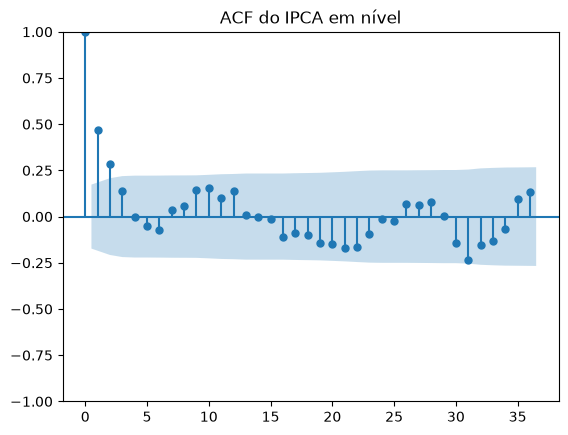

<Figure size 1000x400 with 0 Axes>

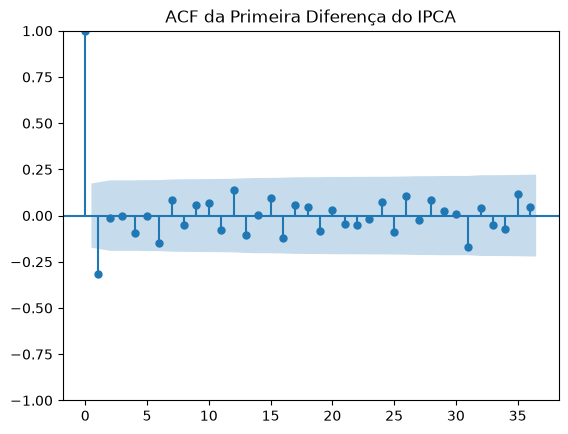

<Figure size 1000x400 with 0 Axes>

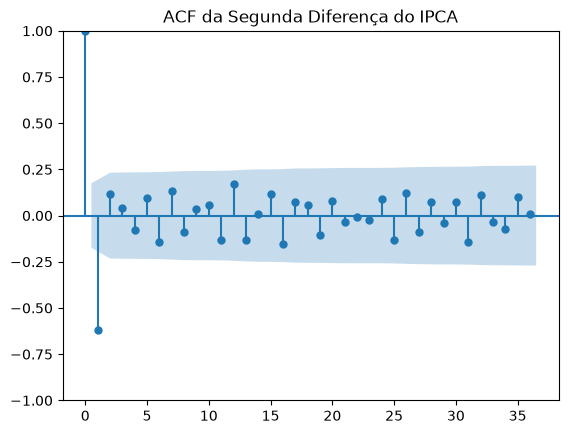


IPCA em nível

Lags principais:
    lag     acf  limite_inferior  limite_superior  significativo
1     1  0.4677           0.2944           0.6409           True
2     2  0.2839           0.0763           0.4916           True
3     3  0.1363          -0.0827           0.3553          False
6     6 -0.0733          -0.2953           0.1486          False
12   12  0.1387          -0.0919           0.3692          False
18   18 -0.0994          -0.3352           0.1363          False
24   24 -0.0153          -0.2655           0.2349          False
30   30 -0.1426          -0.3947           0.1095          False
36   36  0.1332          -0.1339           0.4003          False

Lags significativos entre 1 e 36:
   lag     acf
1    1  0.4677
2    2  0.2839

IPCA - 1ª diferença

Lags principais:
    lag     acf  limite_inferior  limite_superior  significativo
1     1 -0.3186          -0.4925          -0.1447           True
2     2 -0.0119          -0.2026           0.1789          False
3  

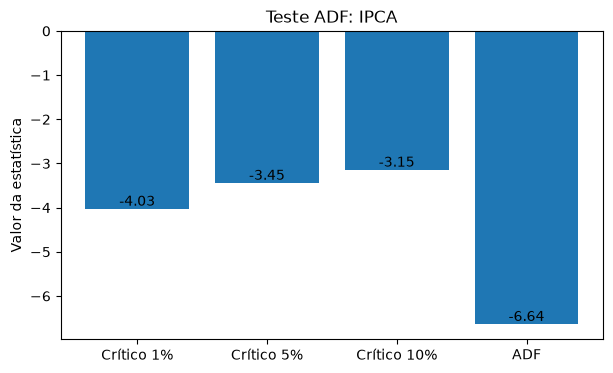

Conclusão: Rejeita-se H0 → Série estacionária
                                                                                       DIFERENÇA DO IPCA                                                                                        
Mostra o comportamento da série original do IPCA, geralmente não estacionária devido a variações econômicas e choques inflacionários.


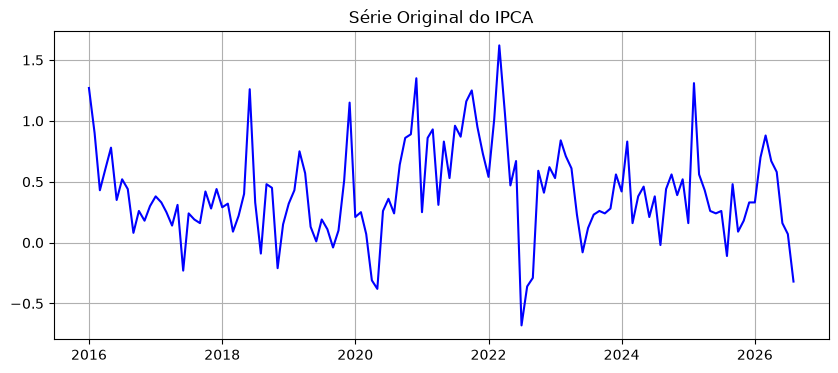

A primeira diferença reduz tendência e torna a série mais próxima de estacionária, removendo variações de nível.


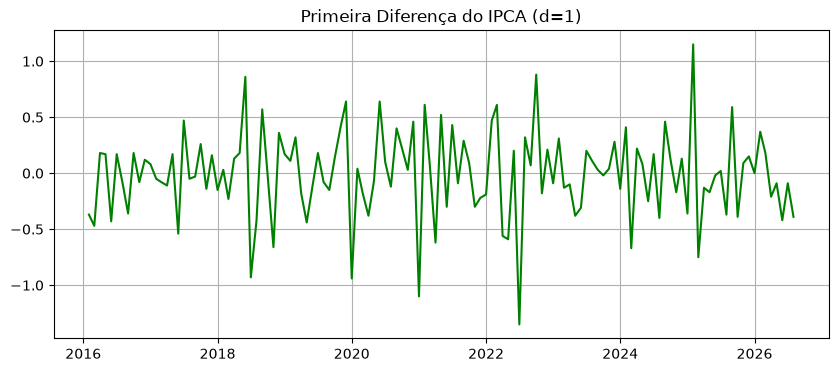

A segunda diferença pode remover estrutura demais, gerando ruído e dificultando interpretação econômica.


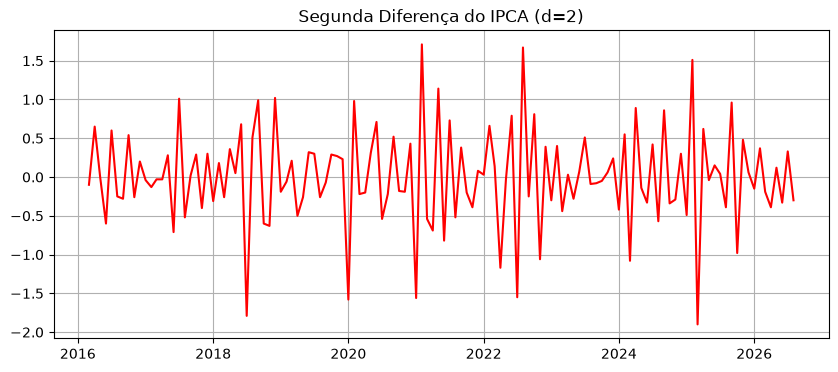

Ordem de diferenciação sazonal identificada: D = 0
Melhor modelo encontrado:
SARIMA(2, 0, 2, 0, 0, 0, 12)
AIC: 96.70144877487688

Resumo do modelo:
                               SARIMAX Results                                
Dep. Variable:                  valor   No. Observations:                  128
Model:               SARIMAX(2, 0, 2)   Log Likelihood                 -43.351
Date:                Sat, 26 Sep 2026   AIC                             96.701
Time:                        18:32:44   BIC                            110.843
Sample:                    01-01-2016   HQIC                           102.446
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5328      0.183      8.386      0.000       1

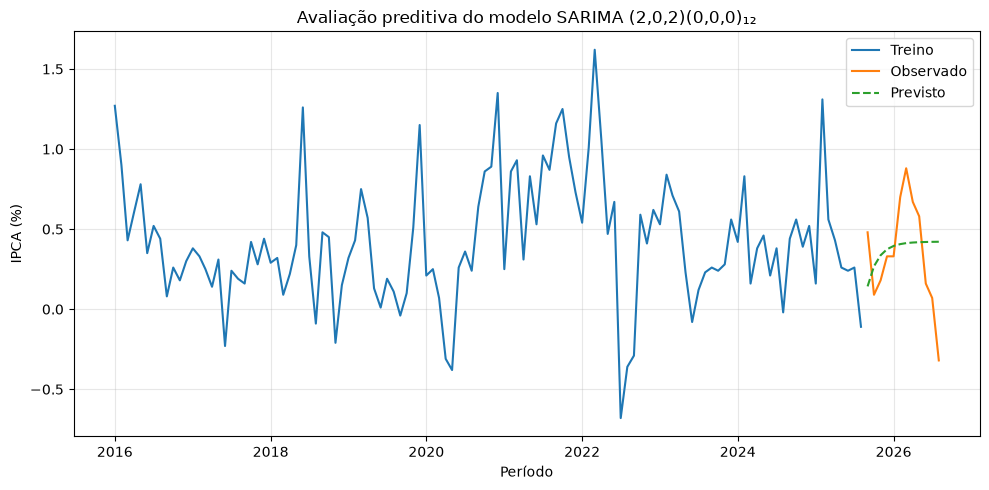

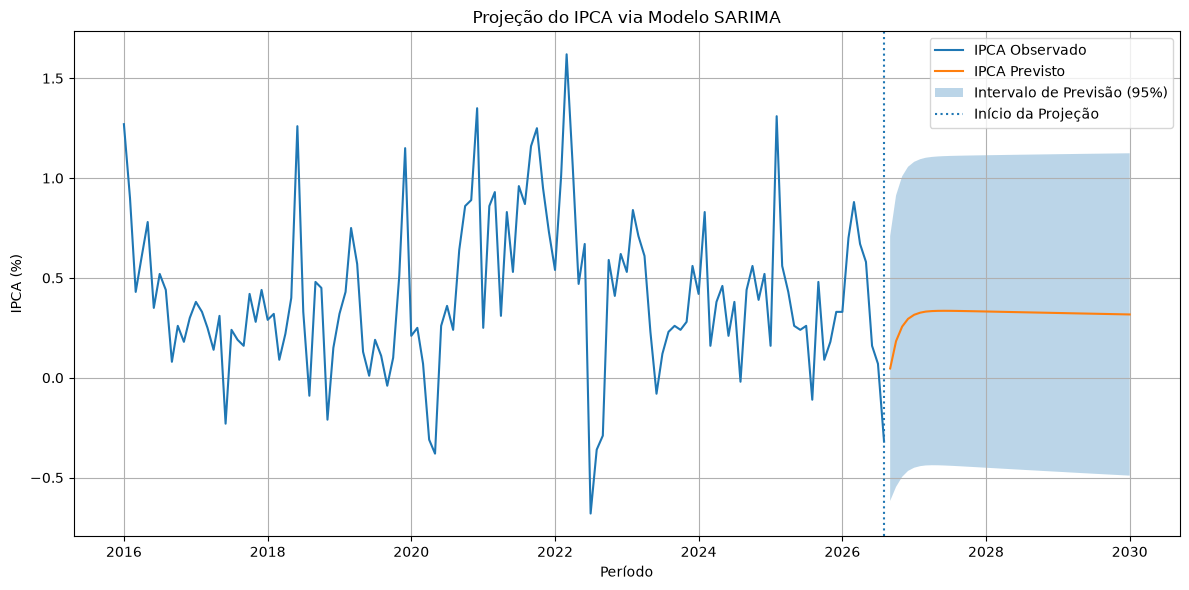


RESUMO DA PROJEÇÃO DO IPCA

Primeiro período projetado: 09/2026
IPCA previsto: 0.0465%
Limite inferior (95%): -0.6168%
Limite superior (95%): 0.7099%

Último período projetado: 01/2030
IPCA previsto: 0.3171%
Limite inferior (95%): -0.4902%
Limite superior (95%): 1.1243%

Menor previsão pontual: 0.0465% em 09/2026
Maior previsão pontual: 0.3353% em 06/2027

                                                                        SELIC                                                                         



<Figure size 1000x400 with 0 Axes>

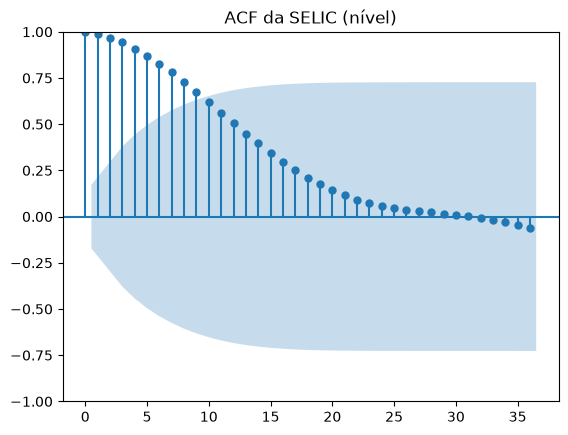

<Figure size 1000x400 with 0 Axes>

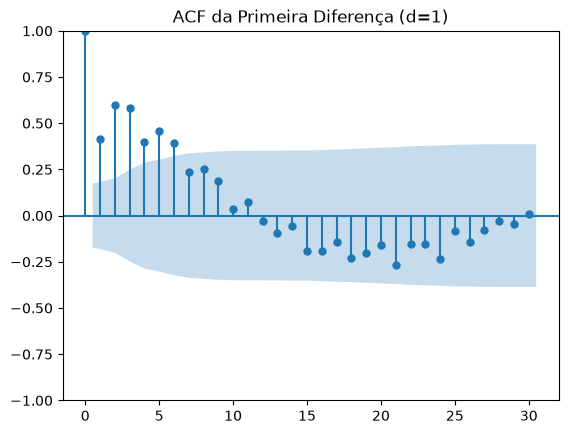

<Figure size 1000x400 with 0 Axes>

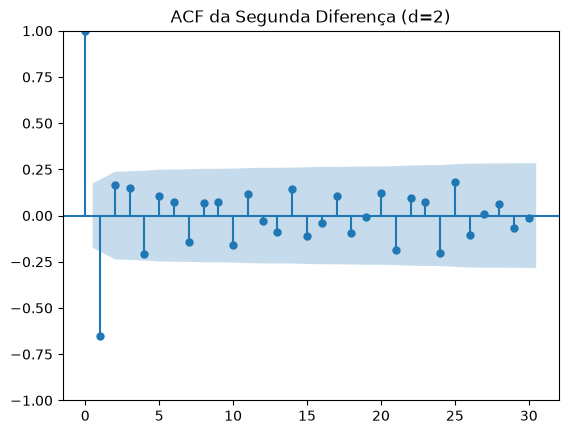

SELIC em nível

Lags principais:
    lag     acf  limite_inferior  limite_superior  significativo
1     1  0.9864           0.8139           1.1590           True
2     2  0.9680           0.6718           1.2641           True
3     3  0.9421           0.5632           1.3209           True
6     6  0.8282           0.2889           1.3676           True
12   12  0.5044          -0.1798           1.1886          False
18   18  0.2106          -0.5110           0.9323          False
24   24  0.0590          -0.6676           0.7856          False
30   30  0.0091          -0.7179           0.7361          False
36   36 -0.0608          -0.7879           0.6663          False

Lags significativos entre 1 e 36:
   lag     acf
1    1  0.9864
2    2  0.9680
3    3  0.9421
4    4  0.9093
5    5  0.8715
6    6  0.8282
7    7  0.7800
8    8  0.7285
9    9  0.6741

SELIC - 1ª diferença

Lags principais:
    lag     acf  limite_inferior  limite_superior  significativo
1     1  0.4157           0

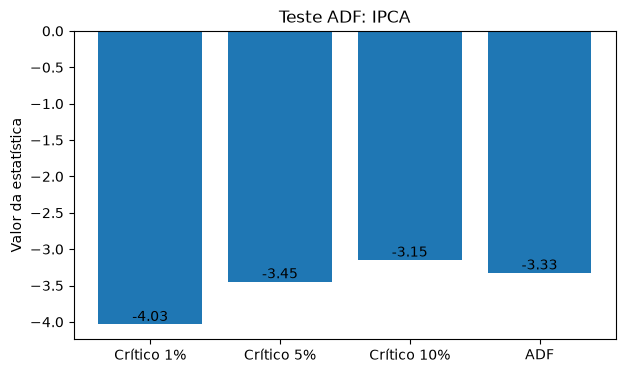

Conclusão: Não se rejeita H0 → Série não estacionária
                                                                                       DIFERENÇA DA SELIC                                                                                       


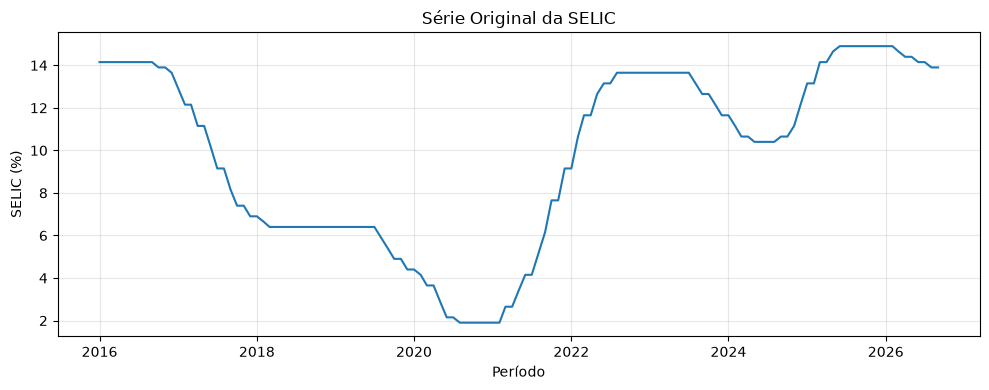

Tipo de regressão: ct
Estatística ADF: -3.3250465870526558
p-valor: 0.0622372438103395
Lags utilizados: 3
Número de observações: 125

Valores críticos:
1%: -4.03308287936
5%: -3.4462147354879997
10%: -3.14799745856


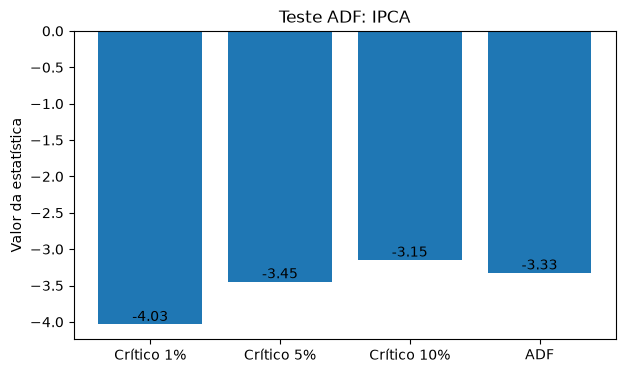

Conclusão: Não se rejeita H0 → Série não estacionária


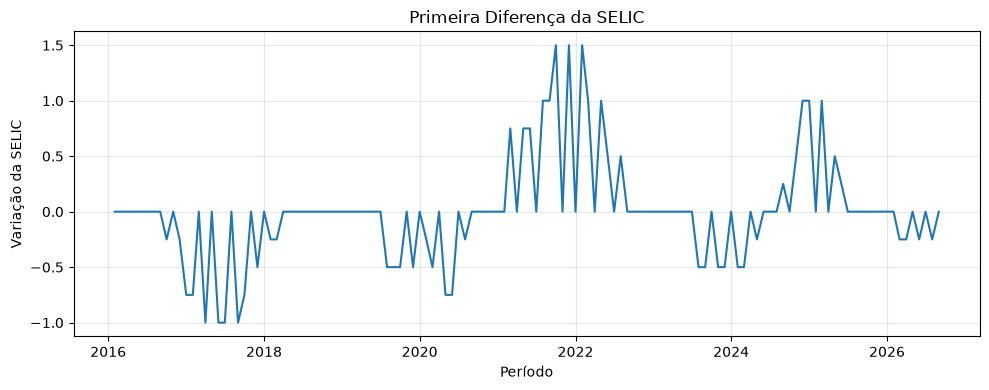

Tipo de regressão: c
Estatística ADF: -2.0771373374374376
p-valor: 0.25380659860504595
Lags utilizados: 2
Número de observações: 125

Valores críticos:
1%: -3.4837793736959997
5%: -2.88495387648
10%: -2.579256976


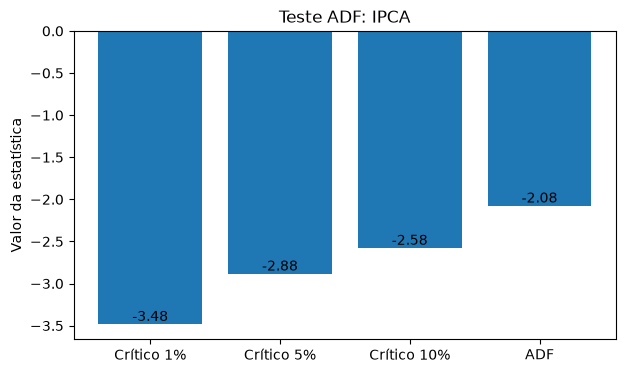

Conclusão: Não se rejeita H0 → Série não estacionária


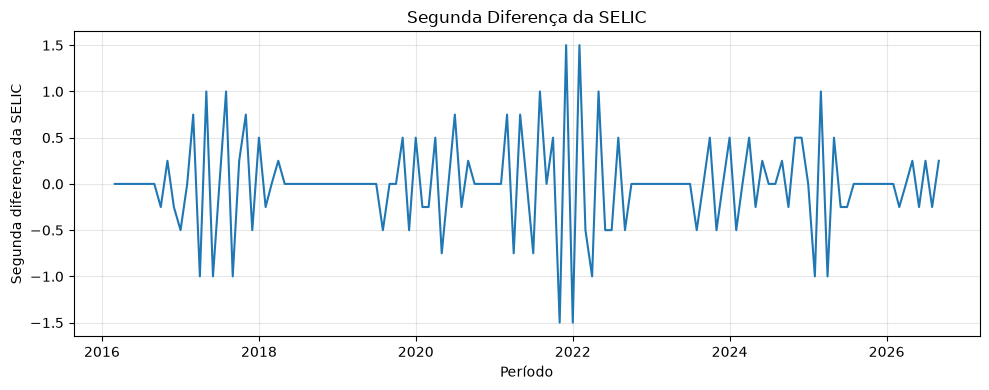

Tipo de regressão: c
Estatística ADF: -16.5548752467456
p-valor: 1.9303617193637577e-29
Lags utilizados: 1
Número de observações: 125

Valores críticos:
1%: -3.4837793736959997
5%: -2.88495387648
10%: -2.579256976


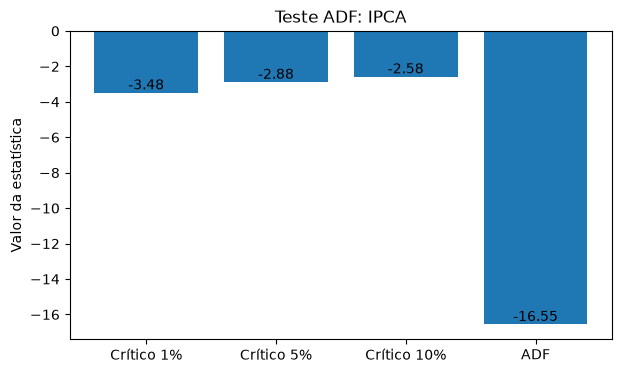

Conclusão: Rejeita-se H0 → Série estacionária
Melhor modelo encontrado:
ARIMA(2, 2, 0)
AIC: 88.97658865462456

Resumo do modelo:
                               SARIMAX Results                                
Dep. Variable:                  valor   No. Observations:                  129
Model:               SARIMAX(2, 2, 0)   Log Likelihood                 -41.488
Date:                Sat, 26 Sep 2026   AIC                             88.977
Time:                        18:32:46   BIC                             97.462
Sample:                    01-01-2016   HQIC                            92.424
                         - 09-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9575      0.065    -14.789      0.000      -1.084      -0.831
ar

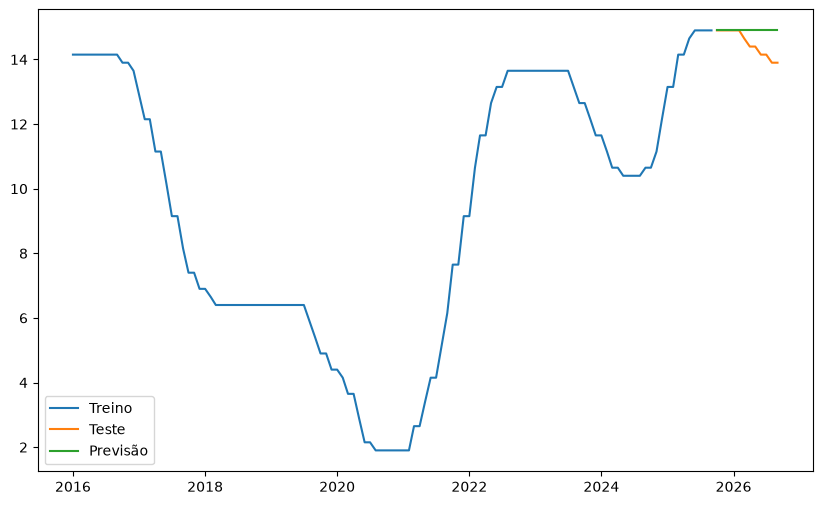

MAE: 0.3958
RMSE: 0.5543
MPE: -2.80%


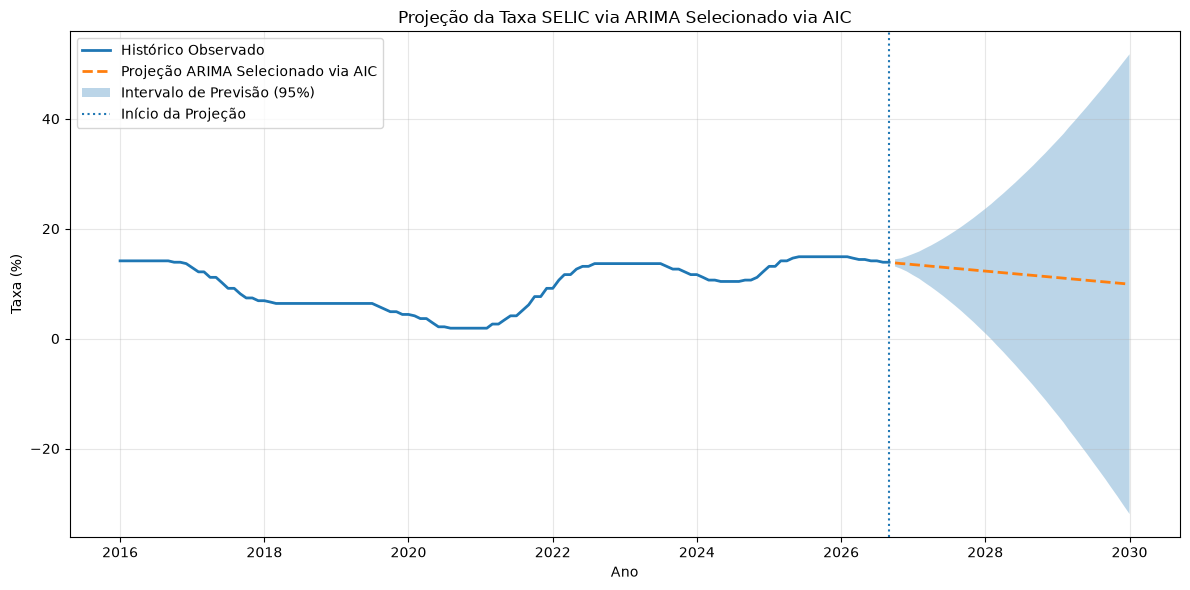


RESUMO DA PROJEÇÃO DA SELIC

Primeiro período projetado: 10/2026
SELIC prevista: 13.7762%
Limite inferior (95%): 13.1153%
Limite superior (95%): 14.4371%

Último período projetado: 01/2030
SELIC prevista: 9.9138%
Limite inferior (95%): -31.9050%
Limite superior (95%): 51.7325%

Menor previsão pontual: 9.9138% em 01/2030
Maior previsão pontual: 13.7762% em 10/2026


,data,periodo_cenario,indicador,cenarios,vl_taxa
0,2016-01-01,observado,SELIC,base,14.150000
1,2016-01-01,observado,IPCA,base,1.270000
2,2016-01-01,observado,IPCA,otimista,1.270000
3,2016-01-01,observado,SELIC,otimista,14.150000
4,2016-01-01,observado,SELIC,pessimista,14.150000
...,...,...,...,...,...
1009,2030-01-01,projetado,SELIC,pessimista,-31.904990
1010,2030-01-01,projetado,SELIC,base,9.913771
1011,2030-01-01,projetado,IPCA,base,0.317069
1012,2030-01-01,projetado,IPCA,pessimista,-0.490157


In [5]:
# chamada do caderno feature_engineering.ipynb
%run feature_engineering.ipynb

In [6]:
print("Observações históricas de IPCA:", len(resultados["IPCA"]["historico"]))
print("Observações históricas de SELIC:", len(resultados["SELIC"]["historico"]))

display(pd.DataFrame(resultados["IPCA"]["historico"]).head())
display(pd.DataFrame(resultados["SELIC"]["historico"]).head())

display(df_selic_mensal)

Observações históricas de IPCA: 128
Observações históricas de SELIC: 2694


,data,valor
0,"Fri, 01 Jan 2016 00:00:00 GMT",1.27
1,"Mon, 01 Feb 2016 00:00:00 GMT",0.90
2,"Tue, 01 Mar 2016 00:00:00 GMT",0.43
3,"Fri, 01 Apr 2016 00:00:00 GMT",0.61
4,"Sun, 01 May 2016 00:00:00 GMT",0.78


,data,valor
0,"Mon, 04 Jan 2016 00:00:00 GMT",14.15
1,"Tue, 05 Jan 2016 00:00:00 GMT",14.15
2,"Wed, 06 Jan 2016 00:00:00 GMT",14.15
3,"Thu, 07 Jan 2016 00:00:00 GMT",14.15
4,"Fri, 08 Jan 2016 00:00:00 GMT",14.15


,valor,indicador
data,,
2016-01-01,14.15,SELIC
2016-02-01,14.15,SELIC
2016-03-01,14.15,SELIC
2016-04-01,14.15,SELIC
2016-05-01,14.15,SELIC
...,...,...
2026-05-01,14.40,SELIC
2026-06-01,14.15,SELIC
2026-07-01,14.15,SELIC


## Chamada dos Cálculos Financeiros BACEN

In [7]:
# chamada do macro_indicadores_processados.ipynb
%run macro_indicadores_processados.ipynb

In [8]:
print(df_iqr.columns.tolist())


['data', 'periodo_cenario', 'cenarios', 'IPCA', 'SELIC', 'juros_real', 'vol_jrs_real_cnr', 'vol_jrs_real_cnr_ano', 'vol_juros_real_12m', 'IPCA_acum_12m', 'SELIC_acum_12m', 'tendencia_IPCA_12m', 'tendencia_SELIC_12m', 'tendencia_IPCA_12m_anual', 'tendencia_SELIC_12m_anual', 'corr_IPCA_SELIC_acum_12m', 'corr_IPCA_juros_real_12m', 'Z_IPCA_acum_12m_12m', 'Z_SELIC_acum_12m_12m', 'Z_juros_real_12m', 'IQR_IPCA_acum_12m_12m', 'outlier_IPCA_acum_12m_12m', 'IQR_SELIC_acum_12m_12m', 'outlier_SELIC_acum_12m_12m', 'IQR_juros_real_12m', 'outlier_juros_real_12m']


In [9]:
teste_1 = df_iqr[
    pd.to_datetime(df_iqr["data"]) == pd.Timestamp("2026-10-01")
].copy()

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

display(teste_1)

,data,periodo_cenario,cenarios,IPCA,SELIC,juros_real,vol_jrs_real_cnr,vol_jrs_real_cnr_ano,vol_juros_real_12m,IPCA_acum_12m,SELIC_acum_12m,tendencia_IPCA_12m,tendencia_SELIC_12m,tendencia_IPCA_12m_anual,tendencia_SELIC_12m_anual,corr_IPCA_SELIC_acum_12m,corr_IPCA_juros_real_12m,Z_IPCA_acum_12m_12m,Z_SELIC_acum_12m_12m,Z_juros_real_12m,IQR_IPCA_acum_12m_12m,outlier_IPCA_acum_12m_12m,IQR_SELIC_acum_12m_12m,outlier_SELIC_acum_12m_12m,IQR_juros_real_12m,outlier_juros_real_12m
130,2026-10-01,projetado,base,0.001835,0.010813,0.008962,0.004807,0.003505,0.003654,0.033523,0.143264,-0.000021,0.000419,-0.000250,0.005030,0.695741,-0.308985,-1.491577,-1.793182,0.139909,0.00734,False,0.002715,False,0.005161,False
300,2026-10-01,projetado,otimista,0.009134,0.011301,0.002147,0.006468,0.004558,0.004146,0.047956,0.143816,0.000568,0.001341,0.006814,0.016087,0.137936,-0.332859,1.304886,-1.566865,-1.249530,0.00377,False,0.002715,False,0.005349,False
470,2026-10-01,projetado,pessimista,-0.005465,0.010323,0.015875,0.007986,0.004994,0.004847,0.019189,0.142710,-0.000563,-0.000510,-0.006755,-0.006118,0.793879,-0.670912,-2.338629,-1.986415,1.296770,0.00734,True,0.002715,False,0.008916,False


In [10]:
teste = df_iqr[
    df_iqr["cenarios"].str.strip().str.lower() == "base"
].copy()

display(teste)

,data,periodo_cenario,cenarios,IPCA,SELIC,juros_real,vol_jrs_real_cnr,vol_jrs_real_cnr_ano,vol_juros_real_12m,IPCA_acum_12m,SELIC_acum_12m,tendencia_IPCA_12m,tendencia_SELIC_12m,tendencia_IPCA_12m_anual,tendencia_SELIC_12m_anual,corr_IPCA_SELIC_acum_12m,corr_IPCA_juros_real_12m,Z_IPCA_acum_12m_12m,Z_SELIC_acum_12m_12m,Z_juros_real_12m,IQR_IPCA_acum_12m_12m,outlier_IPCA_acum_12m_12m,IQR_SELIC_acum_12m_12m,outlier_SELIC_acum_12m_12m,IQR_juros_real_12m,outlier_juros_real_12m
0,2016-01-01,observado,base,0.012700,0.011090,-0.001590,0.004807,0.003316,NaN,0.012700,0.011090,-0.000021,0.000419,-0.00025,0.00503,NaN,NaN,NaN,NaN,NaN,0.000000,False,0.000000,False,0.000000,False
1,2016-02-01,observado,base,0.009000,0.011090,0.002071,0.004807,0.003316,NaN,0.021814,0.022302,-0.000021,0.000419,-0.00025,0.00503,NaN,NaN,NaN,NaN,NaN,0.004557,False,0.005606,False,0.001831,False
2,2016-03-01,observado,base,0.004300,0.011090,0.006761,0.004807,0.003316,NaN,0.026208,0.033639,-0.000021,0.000419,-0.00025,0.00503,NaN,NaN,NaN,NaN,NaN,0.006754,False,0.011275,False,0.004175,False
3,2016-04-01,observado,base,0.006100,0.011090,0.004959,0.004807,0.003316,NaN,0.032468,0.045102,-0.000021,0.000419,-0.00025,0.00503,NaN,NaN,NaN,NaN,NaN,0.008237,False,0.017006,False,0.004254,False
4,2016-05-01,observado,base,0.007800,0.011090,0.003264,0.004807,0.003316,NaN,0.040521,0.056692,-0.000021,0.000419,-0.00025,0.00503,NaN,NaN,NaN,NaN,NaN,0.010654,False,0.022800,False,0.002888,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,2029-09-01,projetado,base,0.003195,0.008210,0.004999,0.004807,0.000248,0.000247,0.039440,0.108530,-0.000021,0.000419,-0.00025,0.00503,0.999997,0.999992,-1.521075,-1.525424,-1.528160,0.000425,False,0.005441,False,0.000377,False
166,2029-10-01,projetado,base,0.003189,0.008135,0.004930,0.004807,0.000248,0.000248,0.039364,0.107541,-0.000021,0.000419,-0.00025,0.00503,0.999996,0.999991,-1.520764,-1.525428,-1.528161,0.000425,False,0.005441,False,0.000378,False
167,2029-11-01,projetado,base,0.003183,0.008059,0.004861,0.004807,0.000248,0.000248,0.039287,0.106552,-0.000021,0.000419,-0.00025,0.00503,0.999996,0.999990,-1.520598,-1.525424,-1.528160,0.000424,False,0.005441,False,0.000378,False
168,2029-12-01,projetado,base,0.003177,0.007984,0.004792,0.004807,0.000248,0.000248,0.039211,0.105563,-0.000021,0.000419,-0.00025,0.00503,0.999996,0.999990,-1.520509,-1.525426,-1.528161,0.000423,False,0.005441,False,0.000378,False


## Chamada do agente assistivo

import json

def preparar_contexto_ia(df_iqr, cenario_alvo="base"):
    df = df_iqr.copy()
    df["data"] = pd.to_datetime(df["data"], errors="coerce")

    df = (
        df.dropna(subset=["data", "cenarios"])
        .sort_values("data")
    )

    contextos = []

    for cenario in df["cenarios"].unique():
        if cenario.strip().lower() != cenario_alvo.lower():
            continue

        df_c = df[df["cenarios"] == cenario].copy()

        if df_c.empty:
            continue

        pontos = df_c[
            df_c["data"].dt.year.between(2026, 2030)
            & df_c["data"].dt.month.isin([1, 6, 12])
        ].copy()

        trajetoria = [
            {
                "data": data.strftime("%Y-%m-%d"),
                "ipca": float(ipca),
                "selic": float(selic),
                "juros_real": float(juros_real),
            }
            for data, ipca, selic, juros_real in pontos[
                ["data", "IPCA", "SELIC", "juros_real"]
            ].itertuples(index=False, name=None)
        ]

        contexto = {
            "cenario": str(cenario),

            "periodo": {
                "data_inicial": str(df_c["data"].min().date()),
                "data_final": str(df_c["data"].max().date()),
            },

            "trajetoria_ipca_selic_juros_real": trajetoria,

            "valores_finais": {
                "ipca": float(df_c["IPCA"].iloc[-1]),
                "selic": float(df_c["SELIC"].iloc[-1]),
                "juros_real": float(df_c["juros_real"].iloc[-1]),
                "ipca_acumulado_12m": float(
                    df_c["IPCA_acum_12m"].iloc[-1]
                ),
                "selic_acumulada_12m": float(
                    df_c["SELIC_acum_12m"].iloc[-1]
                ),
            },

            "tendencias": {
                "ipca_12m": float(df_c["tendencia_IPCA_12m"].iloc[-1]),
                "selic_12m": float(df_c["tendencia_SELIC_12m"].iloc[-1]),
                "ipca_12m_anual": float(
                    df_c["tendencia_IPCA_12m_anual"].iloc[-1]
                ),
                "selic_12m_anual": float(
                    df_c["tendencia_SELIC_12m_anual"].iloc[-1]
                ),
            },

            "volatilidade": {
                "juros_real_cenario": float(
                    df_c["vol_jrs_real_cnr"].mean()
                ),
                "juros_real_cenario_anual": float(
                    df_c["vol_jrs_real_cnr_ano"].mean()
                ),
                "juros_real_12m": float(
                    df_c["vol_juros_real_12m"].mean()
                ),
            },

            "correlacoes": {
                "ipca_selic": float(
                    df_c["corr_IPCA_SELIC_acum_12m"].mean()
                ),
                "ipca_juros_real": float(
                    df_c["corr_IPCA_juros_real_12m"].mean()
                ),
            },

            "alertas": {
                "zscore_ipca_extremos": int(
                    (df_c["Z_IPCA_acum_12m_12m"].abs() > 2).sum()
                ),
                "zscore_selic_extremos": int(
                    (df_c["Z_SELIC_acum_12m_12m"].abs() > 2).sum()
                ),
                "zscore_juros_real_extremos": int(
                    (df_c["Z_juros_real_12m"].abs() > 2).sum()
                ),
                "outliers_ipca": int(
                    df_c["outlier_IPCA_acum_12m_12m"].sum()
                ),
                "outliers_selic": int(
                    df_c["outlier_SELIC_acum_12m_12m"].sum()
                ),
                "outliers_juros_real": int(
                    df_c["outlier_juros_real_12m"].sum()
                ),
            },
        }

        contextos.append(contexto)

    return contextos

In [11]:
import json
import pandas as pd


def preparar_contexto_ia(df_iqr, cenario_alvo="base"):

    df = df_iqr.copy()

    # Garante o formato temporal da coluna de data
    df["data"] = pd.to_datetime(
        df["data"],
        errors="coerce"
    )

    # Remove registros sem data/cenário e ordena cronologicamente
    df = (
        df.dropna(subset=["data", "cenarios"])
        .sort_values("data")
    )

    contextos = []

    for cenario in df["cenarios"].unique():

        # Mantém somente o cenário definido para análise
        if cenario.strip().lower() != cenario_alvo.lower():
            continue

        df_c = df[df["cenarios"] == cenario].copy()

        if df_c.empty:
            continue

        # Seleciona janeiro, junho e dezembro entre 2026 e 2030
        pontos = df_c[
            df_c["data"].dt.year.between(2026, 2030)
            & df_c["data"].dt.month.isin([1, 6, 12])
        ].copy()

        # Trajetória temporal com os valores originais dos indicadores
        trajetoria = []

        for _, row in pontos.iterrows():

            trajetoria.append({
                "data": row["data"].strftime("%Y-%m-%d"),

                "periodo_cenario": str(
                    row["periodo_cenario"]
                ),

                "ipca": float(row["IPCA"]),
                "selic": float(row["SELIC"]),
                "juros_real": float(row["juros_real"]),

                "volatilidade_juros_real_12m": float(
                    row["vol_juros_real_12m"]
                ),

                "ipca_acumulado_12m": float(
                    row["IPCA_acum_12m"]
                ),

                "selic_acumulada_12m": float(
                    row["SELIC_acum_12m"]
                ),

                "tendencia_ipca_12m": float(
                    row["tendencia_IPCA_12m"]
                ),

                "tendencia_selic_12m": float(
                    row["tendencia_SELIC_12m"]
                ),

                "tendencia_ipca_12m_anual": float(
                    row["tendencia_IPCA_12m_anual"]
                ),

                "tendencia_selic_12m_anual": float(
                    row["tendencia_SELIC_12m_anual"]
                ),

                "correlacao_ipca_selic_12m": float(
                    row["corr_IPCA_SELIC_acum_12m"]
                ),

                "correlacao_ipca_juros_real_12m": float(
                    row["corr_IPCA_juros_real_12m"]
                ),

                "zscore_ipca": float(
                    row["Z_IPCA_acum_12m_12m"]
                ),

                "zscore_selic": float(
                    row["Z_SELIC_acum_12m_12m"]
                ),

                "zscore_juros_real": float(
                    row["Z_juros_real_12m"]
                ),

                "iqr_ipca": float(
                    row["IQR_IPCA_acum_12m_12m"]
                ),

                "iqr_selic": float(
                    row["IQR_SELIC_acum_12m_12m"]
                ),

                "iqr_juros_real": float(
                    row["IQR_juros_real_12m"]
                ),

                "outlier_iqr_ipca": bool(
                    row["outlier_IPCA_acum_12m_12m"]
                ),

                "outlier_iqr_selic": bool(
                    row["outlier_SELIC_acum_12m_12m"]
                ),

                "outlier_iqr_juros_real": bool(
                    row["outlier_juros_real_12m"]
                ),
            })

        # Volatilidade agregada do cenário:
        # já é uma métrica consolidada, portanto não é calculada nova média
        vol_cenario = (
            df_c["vol_jrs_real_cnr"]
            .dropna()
            .iloc[0]
        )

        # Volatilidade anual preservada separadamente para cada ano
        volatilidade_anual = (
            df_c[
                ["data", "vol_jrs_real_cnr_ano"]
            ]
            .dropna(subset=["vol_jrs_real_cnr_ano"])
            .assign(
                ano=lambda x: x["data"].dt.year
            )
            .drop_duplicates(subset=["ano"])
            [["ano", "vol_jrs_real_cnr_ano"]]
        )

        volatilidade_anual = [
            {
                "ano": int(row["ano"]),
                "volatilidade_juros_real": float(
                    row["vol_jrs_real_cnr_ano"]
                )
            }
            for _, row in volatilidade_anual.iterrows()
        ]

        contexto = {

            "cenario": str(cenario),

            "periodo": {
                "data_inicial": str(
                    df_c["data"].min().date()
                ),
                "data_final": str(
                    df_c["data"].max().date()
                ),
            },

            # Valores originais nos pontos selecionados
            "trajetoria_indicadores": trajetoria,

            # Valores do último período disponível
            "valores_finais": {
                "ipca": float(
                    df_c["IPCA"].iloc[-1]
                ),
                "selic": float(
                    df_c["SELIC"].iloc[-1]
                ),
                "juros_real": float(
                    df_c["juros_real"].iloc[-1]
                ),
                "ipca_acumulado_12m": float(
                    df_c["IPCA_acum_12m"].iloc[-1]
                ),
                "selic_acumulada_12m": float(
                    df_c["SELIC_acum_12m"].iloc[-1]
                ),
            },

            # Métricas que já possuem natureza agregada
            "volatilidade": {
                "juros_real_cenario": float(
                    vol_cenario
                ),
                "juros_real_por_ano": volatilidade_anual,
            },

            # Contagem das ocorrências em todo o cenário
            "alertas": {

                "zscore_ipca_extremos": int(
                    (
                        df_c["Z_IPCA_acum_12m_12m"].abs() > 2
                    ).sum()
                ),

                "zscore_selic_extremos": int(
                    (
                        df_c["Z_SELIC_acum_12m_12m"].abs() > 2
                    ).sum()
                ),

                "zscore_juros_real_extremos": int(
                    (
                        df_c["Z_juros_real_12m"].abs() > 2
                    ).sum()
                ),

                "outliers_ipca": int(
                    df_c[
                        "outlier_IPCA_acum_12m_12m"
                    ].sum()
                ),

                "outliers_selic": int(
                    df_c[
                        "outlier_SELIC_acum_12m_12m"
                    ].sum()
                ),

                "outliers_juros_real": int(
                    df_c[
                        "outlier_juros_real_12m"
                    ].sum()
                ),
            },
        }

        contextos.append(contexto)

    return contextos

In [12]:
contextos = preparar_contexto_ia(df_iqr)
print(
    json.dumps(
        contextos[0],
        indent=2,
        ensure_ascii=False
    )
)

{
  "cenario": "base",
  "periodo": {
    "data_inicial": "2016-01-01",
    "data_final": "2030-01-01"
  },
  "trajetoria_indicadores": [
    {
      "data": "2026-01-01",
      "periodo_cenario": "observado",
      "ipca": 0.0033,
      "selic": 0.011641575009651461,
      "juros_real": 0.008314138353086253,
      "volatilidade_juros_real_12m": 0.003819438912121079,
      "ipca_acumulado_12m": 0.0444135121281346,
      "selic_acumulada_12m": 0.14607152741597917,
      "tendencia_ipca_12m": -2.0802859200625854e-05,
      "tendencia_selic_12m": 0.00041914550496105723,
      "tendencia_ipca_12m_anual": -0.00024963431040751023,
      "tendencia_selic_12m_anual": 0.005029746059532687,
      "correlacao_ipca_selic_12m": -0.8396042987008021,
      "correlacao_ipca_juros_real_12m": -0.1851994783860568,
      "zscore_ipca": -1.3066780545082932,
      "zscore_selic": 1.3538405590117923,
      "zscore_juros_real": 0.14061328240276164,
      "iqr_ipca": 0.007014505564550799,
      "iqr_selic": 0.

In [15]:
import requests
import json


# ============================================================
# 1. CONFIGURAÇÃO GERAL DO AGENTE
# ============================================================

MODEL = "qwen3:4b-instruct"
OLLAMA_URL = "http://localhost:11434/api/generate"


SYSTEM_PROMPT = """
Você é um agente assistivo para interpretação de resultados
estatísticos previamente calculados.

Sua função é exclusivamente interpretar os dados fornecidos.

REGRAS OBRIGATÓRIAS:

- Utilize exclusivamente os dados presentes na entrada.
- Não invente, altere, complete ou corrija valores.
- Não realize novos cálculos.
- Não recalcule indicadores.
- Não faça novas previsões ou extrapolações.
- Não converta valores decimais em percentuais.
- Não altere escalas ou unidades.
- Não utilize notícias, fatos históricos, teoria econômica
  ou conhecimentos externos.
- Não produza recomendações.
- Não atribua causalidade.
- Não atribua intenções ou decisões ao Banco Central
  ou à política monetária.
- Não associe os resultados a consumo, investimento, emprego,
  crédito, PIB, crescimento econômico, poder de compra,
  empresas ou mercados.
- Não classifique valores como altos, baixos, fortes, fracos,
  estáveis, instáveis, seguros, arriscados, favoráveis
  ou desfavoráveis sem critério explícito fornecido.
- Considere todos os períodos apresentados nos dados.
- Não concentre a interpretação somente no último período.
- Responda somente à tarefa solicitada.
- Utilize linguagem técnica, objetiva, acadêmica e cautelosa.
- Não utilize tabelas.
- Não utilize emojis.
- Não apresente recomendações, próximos passos ou ofertas
  de análises adicionais.
"""


# ============================================================
# 2. FUNÇÃO DE CHAMADA AO OLLAMA
# ============================================================

def interpretar_com_ollama(
    dados,
    tarefa,
    instrucoes_especificas="",
    model=MODEL,
    num_predict=4000
):

    dados_json = json.dumps(
        dados,
        indent=2,
        ensure_ascii=False
    )

    prompt = f"""
TAREFA:

{tarefa}

INSTRUÇÕES ESPECÍFICAS:

{instrucoes_especificas}

FORMATO DA RESPOSTA:

- Produza apenas um parágrafo curto e objetivo.
- Responda somente à tarefa solicitada.
- Considere todos os períodos apresentados.
- Preserve exatamente a escala dos valores.
- Não realize cálculos adicionais.
- Não acrescente introdução geral.
- Não acrescente conclusão além da interpretação solicitada.

DADOS PARA INTERPRETAÇÃO:

{dados_json}
"""

    response = requests.post(
        OLLAMA_URL,
        json={
            "model": model,
            "system": SYSTEM_PROMPT,
            "prompt": prompt,
            "stream": False,
            "options": {
                "num_predict": num_predict,
                "temperature": 0.0,
            },
        },
        timeout=(10, 1000),
    )

    response.raise_for_status()

    return response.json()["response"].strip()


# ============================================================
# 3. VALIDAÇÃO DO CONTEXTO
# ============================================================

if not contextos:
    raise ValueError(
        "Nenhum contexto encontrado. "
        "Execute primeiro: contextos = preparar_contexto_ia(df_iqr)"
    )

contexto_base = contextos[0]

if "trajetoria_indicadores" not in contexto_base:
    raise KeyError(
        'O contexto não possui a chave "trajetoria_indicadores".'
    )

trajetoria = contexto_base["trajetoria_indicadores"]


# ============================================================
# 4. CONFERÊNCIA DAS DATAS
# ============================================================

print("Datas disponíveis para interpretação:\n")

for ponto in trajetoria:
    print(ponto["data"])


# ============================================================
# 5. CONTEXTO EXCLUSIVO PARA IPCA
# ============================================================

dados_ipca = {
    "trajetoria_ipca": [
        {
            "data": ponto["data"],
            "ipca": ponto["ipca"]
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 6. CONTEXTO EXCLUSIVO PARA SELIC
# ============================================================

dados_selic = {
    "trajetoria_selic": [
        {
            "data": ponto["data"],
            "selic": ponto["selic"]
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 7. CONTEXTO EXCLUSIVO PARA JUROS REAIS
# ============================================================

dados_juros_reais = {
    "trajetoria_juros_reais": [
        {
            "data": ponto["data"],
            "juros_real": ponto["juros_real"]
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 8. CONTEXTO EXCLUSIVO PARA TENDÊNCIAS
# ============================================================

dados_tendencias = {
    "tendencias": [
        {
            "data": ponto["data"],
            "tendencia_ipca_12m": ponto["tendencia_ipca_12m"],
            "tendencia_selic_12m": ponto["tendencia_selic_12m"],
            "tendencia_ipca_12m_anual": ponto[
                "tendencia_ipca_12m_anual"
            ],
            "tendencia_selic_12m_anual": ponto[
                "tendencia_selic_12m_anual"
            ],
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 9. CONTEXTO EXCLUSIVO PARA VOLATILIDADE
# ============================================================

dados_volatilidade = {
    "volatilidade_movel_12m": [
        {
            "data": ponto["data"],
            "volatilidade_juros_real_12m": ponto[
                "volatilidade_juros_real_12m"
            ],
        }
        for ponto in trajetoria
    ],
    "volatilidade_agregada": contexto_base.get(
        "volatilidade",
        {}
    )
}


# ============================================================
# 10. CORRELAÇÃO IPCA × SELIC
# ============================================================

dados_corr_ipca_selic = {
    "correlacao_ipca_selic": [
        {
            "data": ponto["data"],
            "correlacao": ponto[
                "correlacao_ipca_selic_12m"
            ],
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 11. CORRELAÇÃO IPCA × JUROS REAIS
# ============================================================

dados_corr_ipca_juros = {
    "correlacao_ipca_juros_reais": [
        {
            "data": ponto["data"],
            "correlacao": ponto[
                "correlacao_ipca_juros_real_12m"
            ],
        }
        for ponto in trajetoria
    ]
}


# ============================================================
# 12. Z-SCORE
# ============================================================

dados_zscore = {
    "zscore_por_periodo": [
        {
            "data": ponto["data"],
            "zscore_ipca": ponto["zscore_ipca"],
            "zscore_selic": ponto["zscore_selic"],
            "zscore_juros_real": ponto[
                "zscore_juros_real"
            ],
        }
        for ponto in trajetoria
    ],

    "quantidades_totais": {
        "zscore_ipca_extremos": contexto_base[
            "alertas"
        ]["zscore_ipca_extremos"],

        "zscore_selic_extremos": contexto_base[
            "alertas"
        ]["zscore_selic_extremos"],

        "zscore_juros_real_extremos": contexto_base[
            "alertas"
        ]["zscore_juros_real_extremos"],
    }
}


# ============================================================
# 13. IQR
# ============================================================

dados_iqr = {
    "sinalizacoes_por_periodo": [
        {
            "data": ponto["data"],
            "outlier_iqr_ipca": ponto[
                "outlier_iqr_ipca"
            ],
            "outlier_iqr_selic": ponto[
                "outlier_iqr_selic"
            ],
            "outlier_iqr_juros_real": ponto[
                "outlier_iqr_juros_real"
            ],
        }
        for ponto in trajetoria
    ],

    "quantidades_totais": {
        "outliers_ipca": contexto_base[
            "alertas"
        ]["outliers_ipca"],

        "outliers_selic": contexto_base[
            "alertas"
        ]["outliers_selic"],

        "outliers_juros_real": contexto_base[
            "alertas"
        ]["outliers_juros_real"],
    }
}


# ============================================================
# 14. DEFINIÇÃO DAS TAREFAS
# ============================================================

tarefas = {

    "ipca": {
        "dados": dados_ipca,

        "tarefa": """
Descreva exclusivamente a evolução do IPCA ao longo de todos
os períodos apresentados.
""",

        "instrucoes": """
Use somente os valores de IPCA fornecidos.

Descreva a sequência temporal observada nos valores.

Não interprete SELIC, juros reais, tendências, correlações,
volatilidade, Z-score ou IQR.

Não atribua causas econômicas às mudanças observadas.
"""
    },


    "selic": {
        "dados": dados_selic,

        "tarefa": """
Descreva exclusivamente a evolução da SELIC ao longo de todos
os períodos apresentados.
""",

        "instrucoes": """
Use somente os valores de SELIC fornecidos.

Descreva a sequência temporal observada nos valores.

Não interprete IPCA, juros reais, tendências, correlações,
volatilidade, Z-score ou IQR.

Não atribua causas econômicas às mudanças observadas.
"""
    },


    "juros_reais": {
        "dados": dados_juros_reais,

        "tarefa": """
Descreva exclusivamente a evolução dos juros reais ao longo
de todos os períodos apresentados.
""",

        "instrucoes": """
Os juros reais já foram calculados previamente.

Utilize exclusivamente os valores fornecidos.

Não recalcule os juros reais.

Não realize subtração entre SELIC e IPCA.

Não utilize informações de IPCA ou SELIC nesta interpretação.
"""
    },


    "tendencias": {
        "dados": dados_tendencias,

        "tarefa": """
Interprete exclusivamente os sinais das tendências fornecidas
para IPCA e SELIC ao longo dos períodos apresentados.
""",

        "instrucoes": """
Valores positivos representam inclinação crescente.

Valores negativos representam inclinação decrescente.

Não classifique tendências como fortes, fracas,
significativas, moderadas ou intensas.

Não explique as causas das tendências.
"""
    },


    "volatilidade": {
        "dados": dados_volatilidade,

        "tarefa": """
Descreva exclusivamente o comportamento da volatilidade
dos juros reais utilizando os valores fornecidos.
""",

        "instrucoes": """
Não classifique a volatilidade como baixa, moderada ou alta.

Não conclua estabilidade, instabilidade, risco,
segurança ou previsibilidade.

Descreva apenas aumento, redução ou mudança observada
nos valores fornecidos.
"""
    },


    "correlacao_ipca_selic": {
        "dados": dados_corr_ipca_selic,

        "tarefa": """
Descreva exclusivamente a evolução da associação estatística
entre IPCA e SELIC ao longo dos períodos apresentados.
""",

        "instrucoes": """
Valores positivos representam associação linear positiva.

Valores negativos representam associação linear negativa.

Não trate associação como causalidade.

Não utilize classificações como fraca, moderada, forte,
muito forte ou perfeita.

Não afirme que IPCA influencia SELIC ou que SELIC influencia IPCA.

Não classifique os coeficientes como estatisticamente
significativos ou insignificantes.
"""
    },


    "correlacao_ipca_juros": {
        "dados": dados_corr_ipca_juros,

        "tarefa": """
Descreva exclusivamente a evolução da associação estatística
entre IPCA e juros reais ao longo dos períodos apresentados.
""",

        "instrucoes": """
Valores positivos representam associação linear positiva.

Valores negativos representam associação linear negativa.

Não trate associação como causalidade.

Não utilize classificações de intensidade.

Não afirme que uma variável influencia ou determina a outra.

Não classifique os coeficientes como estatisticamente
significativos ou insignificantes.
"""
    },


    "zscore": {
        "dados": dados_zscore,

        "tarefa": """
Descreva os valores individuais de Z-score apresentados
nos períodos selecionados e informe separadamente as
quantidades totais de ocorrências com |Z| > 2.
""",

        "instrucoes": """
Os campos "zscore_ipca", "zscore_selic" e
"zscore_juros_real" representam valores individuais
de Z-score.

Valores positivos indicam posição acima da média da janela.

Valores negativos indicam posição abaixo da média da janela.

O critério de sinalização utilizado é |Z| > 2.

Os campos "zscore_ipca_extremos",
"zscore_selic_extremos" e
"zscore_juros_real_extremos" representam QUANTIDADES
DE OCORRÊNCIAS ao longo de todo o cenário.

Exemplo:

zscore_selic_extremos = 13

significa:

13 observações atenderam ao critério |Z| > 2.

NÃO significa Z-score igual a 13.

Não utilize os termos normal, anormal,
normalidade ou distribuição normal.

Não considere incompatível a existência de uma contagem
total de ocorrências e um valor individual que não tenha
atingido |Z| > 2.
"""
    },


    "iqr": {
        "dados": dados_iqr,

        "tarefa": """
Descreva as sinalizações individuais pelo IQR nos períodos
apresentados e informe separadamente as quantidades totais
de observações potencialmente atípicas.
""",

        "instrucoes": """
True significa que aquela observação específica foi
sinalizada como potencialmente atípica pelo critério do IQR.

False significa apenas que aquela observação específica
não foi sinalizada.

Os campos "outliers_ipca",
"outliers_selic" e
"outliers_juros_real" representam QUANTIDADES TOTAIS
de sinalizações ao longo de todo o cenário.

Uma observação False em um período pode coexistir com
quantidade total de outliers maior que zero.

Isso NÃO representa contradição ou erro.

Não trate uma sinalização como anomalia econômica confirmada.
"""
    },
}


# ============================================================
# 15. EXECUÇÃO DAS INTERPRETAÇÕES
# ============================================================

respostas = {}

for nome, config in tarefas.items():

    resposta = interpretar_com_ollama(
        dados=config["dados"],
        tarefa=config["tarefa"],
        instrucoes_especificas=config["instrucoes"],
        model=MODEL,
        num_predict=4000
    )

    respostas[nome] = resposta

    print(f"\n--- {nome} ---\n")
    print(resposta)


# ============================================================
# 16. PREPARAÇÃO DA SÍNTESE FINAL
# ============================================================

dados_sintese = {
    "interpretacoes": respostas
}


# ============================================================
# 17. SÍNTESE FINAL
# ============================================================

sintese = interpretar_com_ollama(
    dados=dados_sintese,

    tarefa="""
Produza uma síntese conjunta das interpretações estatísticas
apresentadas.
""",

    instrucoes_especificas="""
Utilize exclusivamente as interpretações fornecidas.

Não introduza novos valores.

Não realize novos cálculos.

Não introduza informações econômicas externas.

Não atribua causalidade.

Não faça recomendações.

Não classifique o cenário como estável, instável,
favorável, desfavorável, seguro, arriscado,
expansionista ou contracionista.

Produza somente um parágrafo acadêmico e objetivo.
""",

    model=MODEL,
    num_predict=4000
)

respostas["sintese"] = sintese

print("\n--- sintese ---\n")
print(sintese)


# ============================================================
# 18. CONSOLIDAÇÃO DAS RESPOSTAS
# ============================================================

interpretacao_completa = "\n\n".join(
    [
        f"{nome.upper()}\n{resposta}"
        for nome, resposta in respostas.items()
    ]
)


print("\n\n--- INTERPRETAÇÃO COMPLETA ---\n")
print(interpretacao_completa)


# ============================================================
# 19. SALVAMENTO OPCIONAL DOS RESULTADOS
# ============================================================

with open(
    "respostas_agente_assistivo.json",
    "w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        respostas,
        arquivo,
        indent=2,
        ensure_ascii=False
    )

Datas disponíveis para interpretação:

2026-01-01
2026-06-01
2026-12-01
2027-01-01
2027-06-01
2027-12-01
2028-01-01
2028-06-01
2028-12-01
2029-01-01
2029-06-01
2029-12-01
2030-01-01

--- ipca ---

A evolução do IPCA ao longo dos períodos apresentados mostra que, em 2026-01-01, o valor foi de 0,0033; em 2026-06-01, caiu para 0,0016; em 2026-12-01, subiu para 0,002950541412724241; em 2027-01-01, aumentou para 0,003154370256112504; em 2027-06-01, atingiu 0,0033532407000177976; em 2027-12-01, recuou para 0,0033252817579344394; em 2028-01-01, diminuiu para 0,003319060290831625; em 2028-06-01, caiu para 0,0032876856835427335; em 2028-12-01, passou para 0,0032502847646286945; em 2029-01-01, foi de 0,003244091911914618; em 2029-06-01, caiu para 0,0032133039494617677; em 2029-12-01, atingiu 0,003176743765983281; em 2030-01-01, permaneceu em 0,00317069097188482.

--- selic ---

A SELIC apresentou uma evolução sequencial ao longo do tempo, decrescendo de 0,011641575009651461 em 2026-01-01 para 0,

In [ ]:
import requests
import json


def interpretar_com_ollama(prompt, model="qwen3:4b-instruct"):
    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": model,
            "prompt": prompt,
            "stream": False,
            "options": {
                "num_predict": 4000,
                "temperature": 0.2,
            },
        },
        timeout=(10, 1000),
    )
    response.raise_for_status()
    return response.json()["response"]


def criar_prompt(contexto, itens, incluir_sintese=False):
    dados_json = json.dumps(contexto, indent=2, ensure_ascii=False)
    lista_itens = "\n".join(itens)

    instrucao_final = ""
    if incluir_sintese:
        instrucao_final = """
Ao final, apresente uma síntese macroeconômica do cenário baseada
exclusivamente nas informações fornecidas.
"""

    prompt = f"""
Você é um agente assistivo para interpretação de resultados
macroeconômicos.

Os dados fornecidos já foram calculados previamente por modelos
estatísticos e rotinas determinísticas.

As projeções de IPCA e SELIC foram produzidas anteriormente
por modelos ARIMA e SARIMA.

Sua função NÃO é gerar novas previsões.

Sua função é exclusivamente interpretar os resultados
estatísticos fornecidos.

REGRAS OBRIGATÓRIAS:

- Baseie toda a análise exclusivamente nos dados fornecidos.
- Não invente valores.
- Não altere os valores fornecidos.
- Sempre que mencionar um valor numérico, utilize somente valores presentes no contexto fornecido.
- Não realize novos cálculos ou estimativas a partir dos valores apresentados.
- Não faça novas previsões ou extrapolações.
- Não utilize informações, fatos econômicos, notícias ou conhecimentos externos ao contexto fornecido.
- Ao interpretar tendências, utilize exclusivamente os campos de tendência fornecidos.
- Valores positivos de tendência devem ser interpretados como inclinação crescente e valores negativos como inclinação decrescente.
- Ao interpretar correlações, descreva somente direção e intensidade da associação estatística.
- Não trate correlação como causalidade.
- Não afirme relações de causa e efeito entre os indicadores.
- Ao interpretar desvios estatísticos e outliers, utilize exclusivamente os alertas de Z-score e IQR fornecidos no contexto.
- Não classifique uma observação como anômala ou atípica se essa sinalização não estiver presente nos dados fornecidos.
- Caso os dados disponíveis não sejam suficientes para sustentar determinada conclusão, informe explicitamente essa limitação.
- Utilize linguagem técnica, objetiva, acadêmica e cautelosa.

INTERPRETE:

{lista_itens}
{instrucao_final}
Caso alguma seção não possua dados suficientes para interpretação, informe explicitamente essa limitação em vez de produzir uma inferência adicional.

DADOS PARA INTERPRETAÇÃO:

{dados_json}
"""
    return prompt


blocos = {
    "parte_1": [
        "1. comportamento do IPCA ao longo dos períodos apresentados;",
        "2. comportamento da SELIC ao longo dos períodos apresentados;",
        "3. comportamento dos juros reais ao longo dos períodos apresentados;",
    ],

    "parte_2": [
        "4. tendências observadas nos indicadores;",
        "5. comportamento da volatilidade dos juros reais, considerando as medidas fornecidas;",
        "6. evolução da associação estatística entre IPCA e SELIC;",
    ],

    "parte_3": [
        "7. evolução da associação estatística entre IPCA e juros reais;",
        "8. comportamento dos Z-scores nos períodos apresentados e quantidade total de ocorrências com |Z| > 2;",
        "9. sinalizações pelo IQR nos períodos apresentados e quantidade total de valores potencialmente atípicos;",
    ],

    "parte_4": [
        "10. síntese conjunta dos resultados estatísticos apresentados, sem atribuir causalidade ou utilizar informações externas.",
    ],
}

respostas = {}
for i, (nome, itens) in enumerate(blocos.items(), start=1):
    incluir_sintese = (i == len(blocos))  # síntese só no último bloco
    prompt = criar_prompt(contextos[0], itens, incluir_sintese=incluir_sintese)
    respostas[nome] = interpretar_com_ollama(prompt)
    print(f"--- {nome} ---")
    print(respostas[nome])
    print()

interpretacao_completa = "\n\n".join(respostas.values())

In [ ]:
def criar_prompt(contexto):

    dados_json = json.dumps(
        contexto,
        indent=2,
        ensure_ascii=False
    )

    prompt = f"""
Você é um agente assistivo para interpretação de resultados
macroeconômicos.

Os dados fornecidos já foram calculados previamente por modelos
estatísticos e rotinas determinísticas.

As projeções de IPCA e SELIC foram produzidas anteriormente
por modelos ARIMA e SARIMA.

Sua função NÃO é gerar novas previsões.

Sua função é exclusivamente interpretar os resultados
estatísticos fornecidos.

REGRAS OBRIGATÓRIAS:

- Baseie toda a análise exclusivamente nos dados fornecidos.
- Não invente valores.
- Não altere os valores fornecidos.
- Sempre que mencionar um valor numérico, utilize somente valores presentes no contexto fornecido.
- Não realize novos cálculos ou estimativas a partir dos valores apresentados.
- Não faça novas previsões ou extrapolações.
- Não utilize informações, fatos econômicos, notícias ou conhecimentos externos ao contexto fornecido.
- Ao interpretar tendências, utilize exclusivamente os campos de tendência fornecidos.
- Valores positivos de tendência devem ser interpretados como inclinação crescente e valores negativos como inclinação decrescente.
- Ao interpretar correlações, descreva somente direção e intensidade da associação estatística.
- Não trate correlação como causalidade.
- Não afirme relações de causa e efeito entre os indicadores.
- Ao interpretar desvios estatísticos e outliers, utilize exclusivamente os alertas de Z-score e IQR fornecidos no contexto.
- Não classifique uma observação como anômala ou atípica se essa sinalização não estiver presente nos dados fornecidos.
- Caso os dados disponíveis não sejam suficientes para sustentar determinada conclusão, informe explicitamente essa limitação.
- Utilize linguagem técnica, objetiva, acadêmica e cautelosa.

INTERPRETE:

1. comportamento projetado do IPCA;
2. comportamento projetado da SELIC;
3. comportamento dos juros reais;
4. tendências observadas nos indicadores;
5. volatilidade dos juros reais;
6. relação estatística entre IPCA e SELIC;
7. relação estatística entre IPCA e juros reais;
8. presença de desvios estatísticos sinalizados pelo Z-score;
9. presença de outliers valores potencialmente atípicos sinalizados pelo IQR;
10. sinais de estabilidade, variabilidade e desvios estatísticos do cenário, somente quando sustentados pelos indicadores fornecidos.

Ao final, apresente uma síntese macroeconômica do cenário baseada exclusivamente nas informações fornecidas.

Caso alguma seção não possua dados suficientes para interpretação, informe explicitamente essa limitação em vez de produzir uma inferência adicional.

DADOS PARA INTERPRETAÇÃO:

{dados_json}
"""

    return prompt

In [ ]:
prompt = criar_prompt(contextos[0])
print(prompt)

In [ ]:
def criar_prompt(contexto, itens, incluir_sintese=False):
    dados_json = json.dumps(contexto, indent=2, ensure_ascii=False)
    lista_itens = "\n".join(itens)

    instrucao_final = ""
    if incluir_sintese:
        instrucao_final = """
Ao final, apresente uma síntese macroeconômica do cenário baseada
exclusivamente nas informações fornecidas.
"""

    prompt = f"""
Você é um agente assistivo para interpretação de resultados
macroeconômicos.

Os dados fornecidos já foram calculados previamente por modelos
estatísticos e rotinas determinísticas.

As projeções de IPCA e SELIC foram produzidas anteriormente
por modelos ARIMA e SARIMA.

Sua função NÃO é gerar novas previsões.

Sua função é exclusivamente interpretar os resultados
estatísticos fornecidos.

REGRAS OBRIGATÓRIAS:

- Baseie toda a análise exclusivamente nos dados fornecidos.
- Não invente valores.
- Não altere os valores fornecidos.
- Sempre que mencionar um valor numérico, utilize somente valores presentes no contexto fornecido.
- Não realize novos cálculos ou estimativas a partir dos valores apresentados.
- Não faça novas previsões ou extrapolações.
- Não utilize informações, fatos econômicos, notícias ou conhecimentos externos ao contexto fornecido.
- Ao interpretar tendências, utilize exclusivamente os campos de tendência fornecidos.
- Valores positivos de tendência devem ser interpretados como inclinação crescente e valores negativos como inclinação decrescente.
- Ao interpretar correlações, descreva somente direção e intensidade da associação estatística.
- Não trate correlação como causalidade.
- Não afirme relações de causa e efeito entre os indicadores.
- Ao interpretar desvios estatísticos e outliers, utilize exclusivamente os alertas de Z-score e IQR fornecidos no contexto.
- Não classifique uma observação como anômala ou atípica se essa sinalização não estiver presente nos dados fornecidos.
- Caso os dados disponíveis não sejam suficientes para sustentar determinada conclusão, informe explicitamente essa limitação.
- Utilize linguagem técnica, objetiva, acadêmica e cautelosa.

INTERPRETE:

{lista_itens}
{instrucao_final}
Caso alguma seção não possua dados suficientes para interpretação, informe explicitamente essa limitação em vez de produzir uma inferência adicional.

DADOS PARA INTERPRETAÇÃO:

{dados_json}
"""
    return prompt


blocos = {
    "parte_1": [
        "1. comportamento projetado do IPCA;",
        "2. comportamento projetado da SELIC;",
        "3. comportamento dos juros reais;",
    ],
    "parte_2": [
        "4. tendências observadas nos indicadores;",
        "5. volatilidade dos juros reais;",
        "6. relação estatística entre IPCA e SELIC;",
    ],
    "parte_3": [
        "7. relação estatística entre IPCA e juros reais;",
        "8. presença de desvios estatísticos sinalizados pelo Z-score;",
        "9. presença de outliers valores potencialmente atípicos sinalizados pelo IQR;",
    ],
    "parte_4": [
        "10. sinais de estabilidade, variabilidade e desvios estatísticos do cenário, somente quando sustentados pelos indicadores fornecidos.",
    ],
}

respostas = {}
for i, (nome, itens) in enumerate(blocos.items(), start=1):
    incluir_sintese = (i == len(blocos))  # síntese só no último bloco
    prompt = criar_prompt(contextos[0], itens, incluir_sintese=incluir_sintese)
    respostas[nome] = interpretar_com_ollama(prompt)
    print(f"--- {nome} ---")
    print(respostas[nome])
    print()

interpretacao_completa = "\n\n".join(respostas.values())

In [ ]:
import requests

def interpretar_com_ollama(prompt, model="qwen3:4b-instruct"):
    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": model,
            "prompt": prompt,
            "stream": False,
            "options": {
                "num_predict": 4000,
                "temperature": 0.2,
            },
        },
        timeout=(10, 1000),
    )

    response.raise_for_status()
    return response.json()["response"]

In [ ]:
prompt = criar_prompt(contextos[0])
interpretacao = interpretar_com_ollama(prompt)

print(interpretacao)